# 🧠 NeuroLens · Clasificación de tumores cerebrales en resonancia magnética
### UDD · IA para la Gestión Industrial · Certamen 1

**Problema.** Clasificar un corte de resonancia magnética (RM) cerebral en **4 clases**: *glioma*, *meningioma*, *tumor pituitario* o *sin tumor*.
El objetivo es un **prototipo educativo** que muestre cómo un modelo preentrenado puede apoyar el **triaje** (priorizar qué estudios revisa primero un especialista) y cómo un LLM traduce el resultado a lenguaje simple.

| Enfoque | Librería | Modelo | Idea |
|---|---|---|---|
| Línea base | Hugging Face `transformers` | CLIP ViT-B/32 | *Zero-shot*: sin entrenar, solo describiendo las clases en texto |
| Alternativa | `timm` | EfficientNet-B0 | *Transfer learning* sobre ImageNet |
| **Elegido** | `ultralytics` | YOLO-cls nano | *Transfer learning* "en 3 líneas", pensado para producción |

Todos se comparan con **la misma métrica (accuracy balanceada) sobre el mismo conjunto de prueba**.

> ⚠️ Uso exclusivamente educativo. Ningún modelo de este notebook tiene validación clínica y **no entrega diagnósticos**.

El notebook funciona en **Google Colab** (GPU) y en local (Mac con GPU Apple `mps` o CPU).

## 1. Ficha de datos

| Aspecto | Detalle |
|---|---|
| Dataset | *Brain Tumor MRI Dataset* — Masoud Nickparvar (2021), Kaggle |
| Enlace | https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset |
| Licencia | CC0 1.0 (dominio público) |
| Origen | Combinación de tres fuentes públicas: **Figshare** (Cheng et al., 2015 — hospitales de China), **SARTAJ** (Kaggle) y **Br35H** (Kaggle, aporta las imágenes *sin tumor*) |
| Formato | JPG en escala de grises, tamaños variables (≈ 200–630 px), cortes axiales, coronales y sagitales, ponderación T1 con contraste |
| Clases | `glioma` · `meningioma` · `notumor` · `pituitary` |
| Original | 5.712 entrenamiento + 1.311 prueba (en la versión actual: 1.400 + 400 por clase) |

**Cómo dividimos.** Juntamos todas las imágenes, **eliminamos duplicados exactos** (mismo contenido de archivo, ver abajo) y hacemos una división **estratificada 70 / 15 / 15** (entrenamiento / validación / prueba) con semilla fija. Estratificar mantiene la misma proporción de clases en los tres conjuntos.

**Limitaciones conocidas** (se analizan con datos en la sección 2):
1. **Duplicados y fuga de datos**: al combinar fuentes hay imágenes repetidas; si una copia queda en entrenamiento y otra en prueba, la métrica se infla.
2. **Varios cortes por paciente sin identificador**: no podemos dividir por paciente, así que cortes vecinos del mismo paciente pueden quedar en conjuntos distintos → la métrica es **optimista**.
3. **Fuentes distintas por clase**: las imágenes *sin tumor* vienen mayoritariamente de Br35H; el modelo podría aprender el "estilo" de la fuente (tamaño, bordes, contraste) en vez de la anatomía.
4. **Población y equipos acotados**: no sabemos edad, sexo, etnia ni resonador; no representa a la población chilena ni otros tipos de tumor (metástasis, etc.).

In [1]:
# ---- 0. Entorno: funciona igual en Colab y en local ----
import sys, os, subprocess
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    subprocess.run("pip install -q timm ultralytics kagglehub", shell=True)

import hashlib, json, random, shutil, time
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, timm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISP = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
RAIZ = Path("/content") if EN_COLAB else Path.cwd().parent      # raíz del repositorio
DATOS = RAIZ / "datos"                                          # no se sube a GitHub
SALIDA = RAIZ / "modelo"; SALIDA.mkdir(exist_ok=True)                 # lo que usa la app
PESOS_EFF = RAIZ / "runs" / "efficientnet_b0.pt"; PESOS_EFF.parent.mkdir(exist_ok=True)
print("Dispositivo:", DISP, "| torch", torch.__version__, "| timm", timm.__version__)

Dispositivo: mps | torch 2.14.1 | timm 1.0.30


## 2. Descarga, limpieza de duplicados y división 70/15/15

In [2]:
import kagglehub
origen = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
CLASES = ["glioma", "meningioma", "notumor", "pituitary"]       # orden alfabético = orden de ImageFolder

# Recorremos Training/ y Testing/ originales y calculamos un hash MD5 del contenido de cada archivo
filas = []
for parte in ["Training", "Testing"]:
    for c in CLASES:
        for f in sorted((origen / parte / c).iterdir()):
            filas.append({"ruta": f, "clase": c, "parte_original": parte,
                          "md5": hashlib.md5(f.read_bytes()).hexdigest()})
df = pd.DataFrame(filas)
print("Imágenes originales:", len(df))

# ¿Hay imágenes idénticas? ¿Alguna aparece con DOS etiquetas distintas?
dup = df[df.duplicated("md5", keep=False)]
conflicto = dup.groupby("md5")["clase"].nunique().gt(1).sum()
cruzados = dup.groupby("md5")["parte_original"].nunique().gt(1).sum()
print(f"Archivos en grupos duplicados: {len(dup)} | grupos con etiquetas contradictorias: {conflicto} "
      f"| grupos repartidos entre Training y Testing originales: {cruzados}")

# Quitamos las imágenes con etiquetas contradictorias y nos quedamos con una sola copia del resto
md5_malos = dup.groupby("md5").filter(lambda g: g["clase"].nunique() > 1)["md5"].unique()
limpio = df[~df.md5.isin(md5_malos)].drop_duplicates("md5").reset_index(drop=True)
print("Imágenes únicas tras limpiar:", len(limpio))
limpio.clase.value_counts().sort_index()

Imágenes originales: 7200
Archivos en grupos duplicados: 340 | grupos con etiquetas contradictorias: 0 | grupos repartidos entre Training y Testing originales: 0
Imágenes únicas tras limpiar: 7013


clase
glioma        1786
meningioma    1784
notumor       1681
pituitary     1762
Name: count, dtype: int64

/var/folders/fz/mb9tyz0n0fg1tkqcg9hsfvp80000gn/T/ipykernel_45022/117554452.py:14: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tabla["total"] = tabla.sum(1)


,train,val,test,total,% del total
clase,,,,,
glioma,1250,268,268,1786,25.5
meningioma,1249,267,268,1784,25.4
pituitary,1233,265,264,1762,25.1
notumor,1177,252,252,1681,24.0


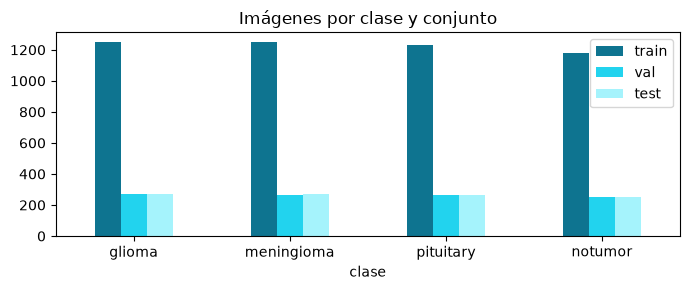

In [3]:
# División estratificada: 70 % train, 15 % val, 15 % test
train, resto = train_test_split(limpio, test_size=0.30, stratify=limpio.clase, random_state=SEMILLA)
val, test = train_test_split(resto, test_size=0.50, stratify=resto.clase, random_state=SEMILLA)

# Carpetas datos/<split>/<clase>/ : el formato que entienden timm (ImageFolder) y YOLO
shutil.rmtree(DATOS, ignore_errors=True)
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    for _, f in parte.iterrows():
        destino = DATOS / nombre / f.clase / f"{f.md5[:12]}.jpg"
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(f.ruta, destino)

tabla = pd.DataFrame({n: p.clase.value_counts() for n, p in [("train", train), ("val", val), ("test", test)]})
tabla["total"] = tabla.sum(1)
tabla["% del total"] = (100 * tabla.total / tabla.total.sum()).round(1)
display(tabla)
tabla[["train", "val", "test"]].plot.bar(figsize=(7, 3), rot=0, color=["#0e7490", "#22d3ee", "#a5f3fc"],
                                          title="Imágenes por clase y conjunto")
plt.tight_layout(); plt.show()

**Desbalance.** Ver tabla: tras eliminar duplicados las clases quedan **levemente desbalanceadas** (la limpieza afecta más a algunas clases). No es un desbalance fuerte, pero igual usamos **accuracy balanceada** como métrica principal para que cada clase pese lo mismo.

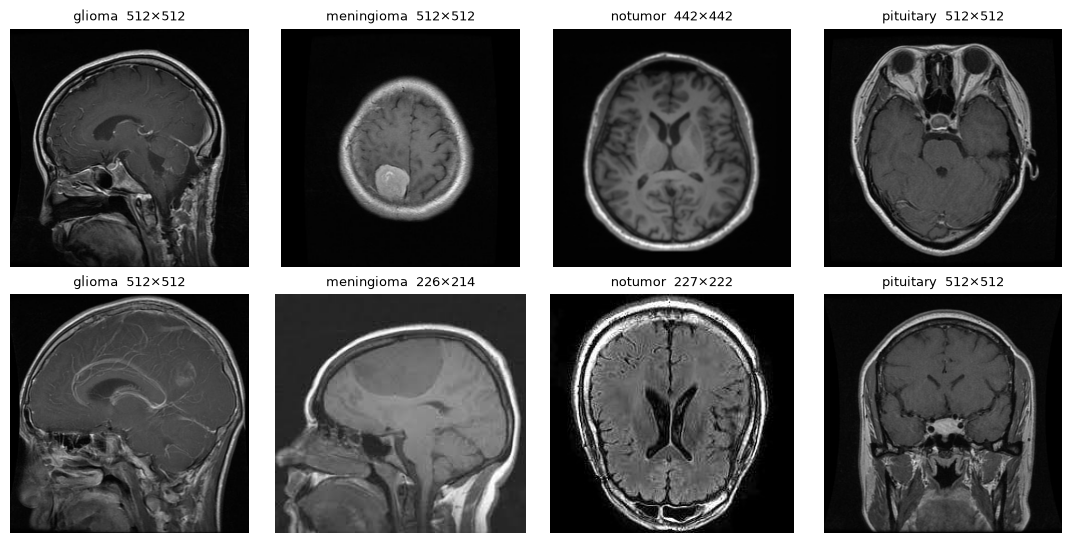

In [4]:
# Una muestra de cada clase
fig, ejes = plt.subplots(2, 4, figsize=(11, 5.5))
for j, c in enumerate(CLASES):
    for i, f in enumerate(random.Random(j).sample(sorted((DATOS / "train" / c).iterdir()), 2)):
        im = Image.open(f)
        ejes[i, j].imshow(im, cmap="gray"); ejes[i, j].axis("off")
        ejes[i, j].set_title(f"{c}  {im.size[0]}×{im.size[1]}", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Evaluación común

Los tres enfoques se evalúan sobre el **mismo conjunto de prueba completo** (que ningún modelo vio al entrenar ni al elegir hiperparámetros).
Métrica principal: **accuracy balanceada** = promedio del *recall* de cada clase (azar = 25 %). Cada enfoque solo debe aportar una función que devuelva las probabilidades de las 4 clases para una lista de rutas.

In [5]:
PRUEBA = [(p, c) for c in CLASES for p in sorted((DATOS / "test" / c).iterdir())]
Y_TEST = np.array([CLASES.index(c) for _, c in PRUEBA])
RESULTADOS = {}

NT = CLASES.index("notumor")

def evaluar(nombre, probs, tamano_mb):
    """Guarda las métricas de un enfoque a partir de su matriz de probabilidades (n_test × 4)."""
    pred = probs.argmax(1)
    fn = int(((Y_TEST != NT) & (pred == NT)).sum())          # tumor clasificado como "sin tumor"
    RESULTADOS[nombre] = {"balanced_accuracy": balanced_accuracy_score(Y_TEST, pred),
                          "accuracy": accuracy_score(Y_TEST, pred), "falsos_negativos": fn,
                          "tamano_mb": tamano_mb, "pred": pred, "probs": probs}
    print(f"{nombre}: accuracy balanceada = {RESULTADOS[nombre]['balanced_accuracy']:.1%} "
          f"| accuracy = {RESULTADOS[nombre]['accuracy']:.1%} | falsos negativos = {fn}")

## 4. Línea base · CLIP *zero-shot* (sin entrenar)

CLIP compara la imagen con **frases que nosotros escribimos** y elige la más parecida. No necesita entrenamiento: sirve para medir **cuánto aporta adaptar un modelo a nuestros datos**.

In [6]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DISP).eval()
clip_prep = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
TEXTOS = {   # una descripción en inglés por clase, en el orden de CLASES
    "glioma":     "a brain MRI scan showing a glioma, an irregular infiltrating tumor inside the brain tissue",
    "meningioma": "a brain MRI scan showing a meningioma, a round well-defined tumor attached to the skull lining",
    "notumor":    "a brain MRI scan of a healthy normal brain with no tumor",
    "pituitary":  "a brain MRI scan showing a pituitary tumor at the base of the brain near the sella",
}

@torch.no_grad()
def probs_clip(rutas, lote=64):
    salida = []
    for i in range(0, len(rutas), lote):
        imgs = [Image.open(r).convert("RGB") for r in rutas[i:i + lote]]
        x = clip_prep(text=list(TEXTOS.values()), images=imgs, return_tensors="pt", padding=True).to(DISP)
        salida.append(clip(**x).logits_per_image.softmax(1).cpu().numpy())
    return np.concatenate(salida)

evaluar("CLIP zero-shot", probs_clip([p for p, _ in PRUEBA]), tamano_mb=605)

W1019 18:05:41.315000 45022 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP zero-shot: accuracy balanceada = 24.6% | accuracy = 25.1% | falsos negativos = 0


## 5. Enfoque 2 · EfficientNet-B0 con *transfer learning* (`timm`)

1. Cargamos EfficientNet-B0 **preentrenada en ImageNet** y reemplazamos su última capa por una de **4 salidas**.
2. Entrenamos con **aumentación de datos** (recortes, volteos, cambios de brillo) para que el modelo no memorice y tolere variaciones de equipo.
3. Tasa de aprendizaje pequeña (3e-4) con *cosine decay*: ajustamos sin "olvidar" lo que ya sabe.
4. Tras cada época medimos la **accuracy balanceada en validación** y guardamos **el mejor modelo** (no el último).

In [7]:
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES)).to(DISP)
cfg = timm.data.resolve_model_data_config(modelo)                 # 224 px + normalización ImageNet
prep_train = timm.data.create_transform(**cfg, is_training=True, hflip=0.5, color_jitter=0.2,
                                        scale=(0.7, 1.0), auto_augment=None, re_prob=0.0)
prep = timm.data.create_transform(**cfg)                          # sin aumentación para val/test/app

ds_train = ImageFolder(DATOS / "train", transform=prep_train)
ds_val = ImageFolder(DATOS / "val", transform=prep)
assert ds_train.classes == CLASES
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, num_workers=0)
dl_val = DataLoader(ds_val, batch_size=64, num_workers=0)

EPOCAS = 8
opt = torch.optim.AdamW(modelo.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS * len(dl_train))
perdida = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

@torch.no_grad()
def predecir_loader(m, dl):
    m.eval(); P, Y = [], []
    for x, y in dl:
        P.append(m(x.to(DISP)).softmax(1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

historia, mejor = [], 0
for epoca in range(EPOCAS):
    modelo.train(); suma, t0 = 0.0, time.time()
    for x, y in dl_train:
        opt.zero_grad()
        l = perdida(modelo(x.to(DISP)), y.to(DISP))
        l.backward(); opt.step(); sched.step(); suma += l.item()
    p_val, y_val = predecir_loader(modelo, dl_val)
    bacc = balanced_accuracy_score(y_val, p_val.argmax(1))
    historia.append({"epoca": epoca + 1, "perdida_train": suma / len(dl_train), "bacc_val": bacc})
    if bacc > mejor:                                   # guardamos el mejor según VALIDACIÓN
        mejor = bacc; torch.save(modelo.state_dict(), PESOS_EFF)
    print(f"época {epoca + 1} | pérdida {suma / len(dl_train):.3f} | bacc val {bacc:.1%} | {time.time() - t0:.0f}s")

modelo.load_state_dict(torch.load(PESOS_EFF)); modelo.eval()
print(f"Mejor accuracy balanceada en validación: {mejor:.1%}")

época 1 | pérdida 1.009 | bacc val 90.1% | 58s


época 2 | pérdida 0.540 | bacc val 95.6% | 58s


época 3 | pérdida 0.448 | bacc val 96.4% | 57s


época 4 | pérdida 0.421 | bacc val 97.7% | 57s


época 5 | pérdida 0.404 | bacc val 97.7% | 59s


época 6 | pérdida 0.392 | bacc val 97.6% | 59s


época 7 | pérdida 0.386 | bacc val 97.7% | 58s


época 8 | pérdida 0.385 | bacc val 97.6% | 58s
Mejor accuracy balanceada en validación: 97.7%


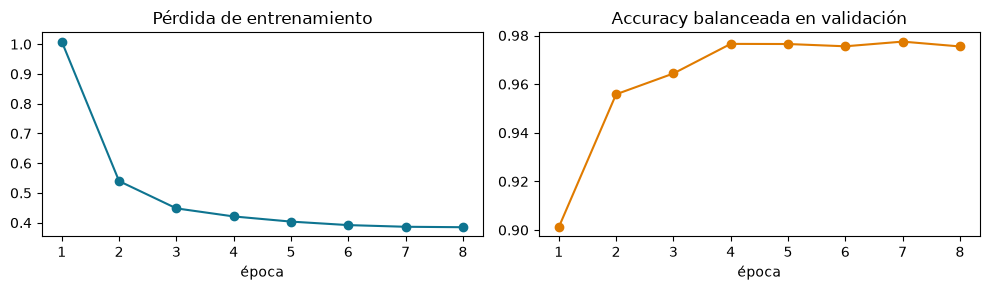

In [8]:
h = pd.DataFrame(historia)
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3))
a.plot(h.epoca, h.perdida_train, "o-", color="#0e7490"); a.set_title("Pérdida de entrenamiento"); a.set_xlabel("época")
b.plot(h.epoca, h.bacc_val, "o-", color="#e07b00"); b.set_title("Accuracy balanceada en validación"); b.set_xlabel("época")
plt.tight_layout(); plt.show()

In [9]:
# Evaluación en PRUEBA
dl_test = DataLoader(ImageFolder(DATOS / "test", transform=prep), batch_size=64, num_workers=0)
p_test, y_chk = predecir_loader(modelo, dl_test)
assert (y_chk == Y_TEST).all()
evaluar("EfficientNet-B0 (timm)", p_test, tamano_mb=os.path.getsize(PESOS_EFF) / 1e6)
cpu = timm.create_model("efficientnet_b0", num_classes=4); cpu.load_state_dict(modelo.state_dict()); cpu.eval()

EfficientNet-B0 (timm): accuracy balanceada = 97.6% | accuracy = 97.5% | falsos negativos = 5


EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bi

## 6. Enfoque 3 (elegido) · YOLO-cls nano (`ultralytics`)

YOLO lee directamente la carpeta `datos/` (`train/` y `val/`) y se encarga del entrenamiento y la aumentación.

In [10]:
from IPython.utils.capture import capture_output
from ultralytics import YOLO
try:
    yolo = YOLO("yolo26n-cls.pt")
except Exception:
    yolo = YOLO("yolo11n-cls.pt")
with capture_output():          # oculta las barras de progreso de YOLO (miles de líneas)
    yolo.train(data=str(DATOS), epochs=10, imgsz=224, batch=32, device=DISP, seed=SEMILLA,
               plots=False, verbose=False, project=str(RAIZ / "runs"), name="yolo", exist_ok=True)
pesos_yolo = Path(yolo.trainer.best)
yolo = YOLO(pesos_yolo)          # recargamos el mejor modelo según validación
print("Mejor modelo YOLO:", pesos_yolo.name)

def probs_yolo(rutas, device=DISP):
    salida = []
    for r in yolo.predict([str(p) for p in rutas], imgsz=224, verbose=False, stream=True, device=device):
        # YOLO ordena sus clases alfabéticamente igual que CLASES
        salida.append(r.probs.data.cpu().numpy())
    return np.stack(salida)

assert list(yolo.names.values()) == CLASES
evaluar("YOLO-cls nano", probs_yolo([p for p, _ in PRUEBA]), tamano_mb=os.path.getsize(pesos_yolo) / 1e6)

Ultralytics 8.4.182 🚀 Python-3.12.13 torch-2.14.1 MPS (Apple M5 Pro)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/namonaque/Documents/Código/UDD/IA para la gestion industrial/certamen 1/datos, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=Tr

train: /Users/namonaque/Documents/Código/UDD/IA para la gestion industrial/certamen 1/datos/train... found 4909 images in 4 classes ✅ 


val: /Users/namonaque/Documents/Código/UDD/IA para la gestion industrial/certamen 1/datos/val... found 1052 images in 4 classes ✅ 


test: /Users/namonaque/Documents/Código/UDD/IA para la gestion industrial/certamen 1/datos/test... found 1052 images in 4 classes ✅ 


...

test: /Users/namonaque/Documents/Código/UDD/IA para la gestion industrial/certamen 1/datos/test... found 1052 images in 4 classes ✅ 


                   all      0.975          1


Speed: 0.0ms preprocess, 0.1ms inference, 0.0ms loss, 0.0ms postprocess per image


Mejor modelo YOLO: best.pt


YOLO-cls nano: accuracy balanceada = 98.4% | accuracy = 98.4% | falsos negativos = 4


## 7. Comparación con la misma métrica

,balanced_accuracy,accuracy,falsos_negativos,tamano_mb,ms_por_imagen
CLIP zero-shot,24.6%,25.1%,0,605.0,45
EfficientNet-B0 (timm),97.6%,97.5%,5,16.3,240
YOLO-cls nano,98.4%,98.4%,4,3.2,6


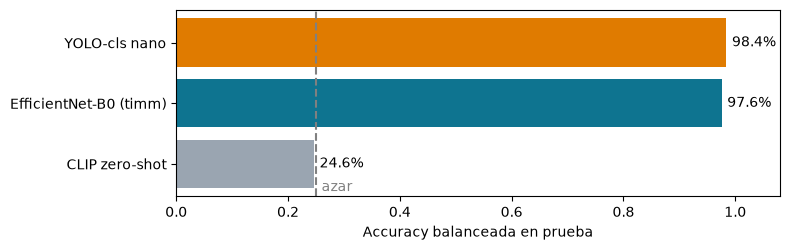

In [11]:
# Velocidad: los 3 modelos en CPU, de a una imagen (así correrá en el servidor gratuito)
def ms_cpu(predecir, n=20):
    predecir(); t0 = time.time()
    for _ in range(n): predecir()
    return 1000 * (time.time() - t0) / n

ruta1 = PRUEBA[0][0]
with torch.no_grad():
    x1 = prep(Image.open(ruta1).convert("RGB")).unsqueeze(0)
    RESULTADOS["EfficientNet-B0 (timm)"]["ms_por_imagen"] = ms_cpu(lambda: cpu(x1))
    RESULTADOS["YOLO-cls nano"]["ms_por_imagen"] = ms_cpu(lambda: probs_yolo([ruta1], device="cpu"))
    clip.to("cpu"); DISP_CLIP, DISP = DISP, "cpu"
    RESULTADOS["CLIP zero-shot"]["ms_por_imagen"] = ms_cpu(lambda: probs_clip([ruta1]), n=5)
    DISP = DISP_CLIP

comp = pd.DataFrame(RESULTADOS).T[["balanced_accuracy", "accuracy", "falsos_negativos", "tamano_mb", "ms_por_imagen"]]
display(comp.style.format({"balanced_accuracy": "{:.1%}", "accuracy": "{:.1%}", "tamano_mb": "{:.1f}",
                           "ms_por_imagen": "{:.0f}"}))
plt.figure(figsize=(8, 2.6))
plt.barh(comp.index, comp.balanced_accuracy, color=["#9aa5b1", "#0e7490", "#e07b00"])
for i, v in enumerate(comp.balanced_accuracy): plt.text(v + 0.01, i, f"{v:.1%}", va="center")
plt.axvline(0.25, ls="--", color="gray"); plt.text(0.26, -0.45, "azar", color="gray")
plt.xlim(0, 1.08); plt.xlabel("Accuracy balanceada en prueba"); plt.tight_layout(); plt.show()

### ¿Por qué elegimos YOLO-cls nano?

- **CLIP sin entrenar queda en el azar (≈25 %)**: un modelo general, entrenado con fotos de internet, no sabe distinguir tumores en una RM. Adaptar el modelo con datos del dominio es indispensable.
- **YOLO-cls nano y EfficientNet-B0 rinden muy parecido**, pero YOLO gana en **todas** las columnas que importan para este problema:
  - mayor **accuracy balanceada** en prueba (≈98 % vs ≈97,6 %),
  - **menos falsos negativos** (tumor clasificado como "sin tumor"), que es el error más costoso,
  - es **5 veces más liviano** (≈3 MB vs ≈16 MB) y **mucho más rápido en CPU**, lo que importa porque la app corre en un servidor gratuito sin GPU.
- La diferencia de accuracy es pequeña (unas pocas imágenes de 1.052), así que **el argumento decisivo es el conjunto**: igual o mejor desempeño, menos errores graves y menor costo de operación.
- EfficientNet sigue siendo una buena alternativa: Grad-CAM es más directo en `timm`, pero lo implementamos también para YOLO (sección 11).

## 8. Métricas detalladas del modelo elegido en prueba

              precision    recall  f1-score   support

      Glioma      0.985     0.966     0.976       268
  Meningioma      0.967     0.993     0.980       268
   Sin tumor      0.984     1.000     0.992       252
  Pituitario      1.000     0.977     0.989       264

    accuracy                          0.984      1052
   macro avg      0.984     0.984     0.984      1052
weighted avg      0.984     0.984     0.984      1052



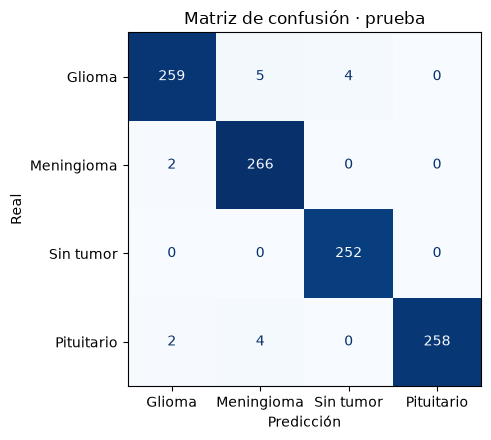

In [12]:
p_test = RESULTADOS["YOLO-cls nano"]["probs"]      # desde aquí, todo es sobre el modelo elegido
pred = p_test.argmax(1)
NOMBRES = ["Glioma", "Meningioma", "Sin tumor", "Pituitario"]
print(classification_report(Y_TEST, pred, target_names=NOMBRES, digits=3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(Y_TEST, pred), display_labels=NOMBRES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); plt.title("Matriz de confusión · prueba"); plt.tight_layout(); plt.show()

## 9. El error más costoso: un tumor clasificado como "sin tumor"

En un sistema de apoyo al triaje, **un falso negativo** (decir *sin tumor* cuando sí hay) es el peor error: el estudio podría quedar al final de la fila y retrasar el diagnóstico y tratamiento. Confundir un tipo de tumor con otro también es grave, pero el caso igual llega al especialista. Un falso positivo (*tumor* en un cerebro sano) genera ansiedad y costos de revisión, pero se corrige al revisar.

Por eso medimos aparte la **sensibilidad para "hay tumor"** (tumor vs. sin tumor, juntando las 3 clases de tumor).

Sensibilidad 'hay tumor': 99.50%  | Especificidad: 100.00%
Falsos negativos (tumor → 'sin tumor'): 4 de 800 | Falsos positivos: 0


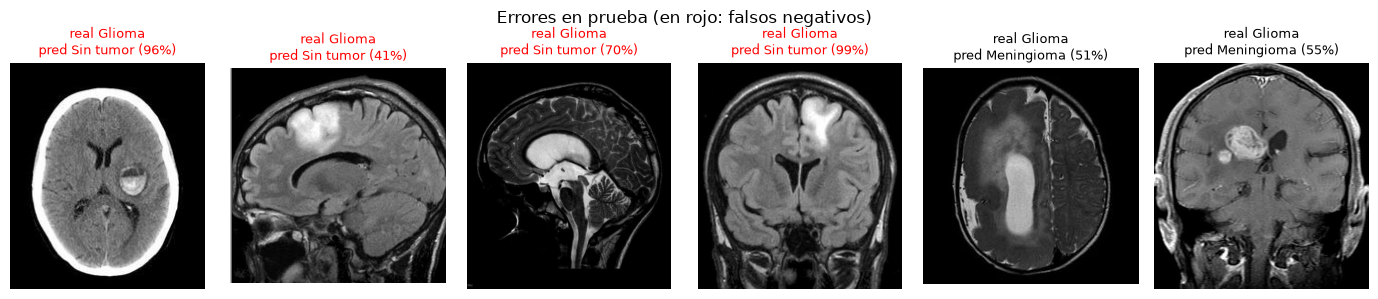

In [13]:
NT = CLASES.index("notumor")
hay_tumor, dice_tumor = Y_TEST != NT, pred != NT
fn = np.where(hay_tumor & ~dice_tumor)[0]; fp = np.where(~hay_tumor & dice_tumor)[0]
sens = (hay_tumor & dice_tumor).sum() / hay_tumor.sum(); esp = (~hay_tumor & ~dice_tumor).sum() / (~hay_tumor).sum()
print(f"Sensibilidad 'hay tumor': {sens:.2%}  | Especificidad: {esp:.2%}")
print(f"Falsos negativos (tumor → 'sin tumor'): {len(fn)} de {hay_tumor.sum()} | Falsos positivos: {len(fp)}")

errores = np.where(pred != Y_TEST)[0]
muestra = list(fn) + [i for i in errores if i not in fn]
fig, ejes = plt.subplots(1, min(6, len(muestra)) or 1, figsize=(14, 3), squeeze=False)
for ax, i in zip(ejes[0], muestra[:6]):
    ax.imshow(Image.open(PRUEBA[i][0]), cmap="gray"); ax.axis("off")
    ax.set_title(f"real {NOMBRES[Y_TEST[i]]}\npred {NOMBRES[pred[i]]} ({p_test[i].max():.0%})", fontsize=9,
                 color="red" if i in fn else "black")
plt.suptitle("Errores en prueba (en rojo: falsos negativos)"); plt.tight_layout(); plt.show()

## 10. Umbral de confianza calibrado en validación

La app avisa **"requiere revisión humana"** cuando la confianza (probabilidad de la clase ganadora) es baja. En vez de inventar un umbral, lo elegimos con el **conjunto de validación**: el **menor umbral** tal que las predicciones por sobre él tengan **≥ 99 % de acierto**. Luego verificamos qué pasa en prueba.

Umbral elegido: 0.93
Prueba · sobre el umbral: 94.7% de las imágenes con 99.3% de acierto
Prueba · bajo el umbral (a revisión humana): 5.3% con 82.1% de acierto
Falsos negativos que quedan sobre el umbral: 2 de 4


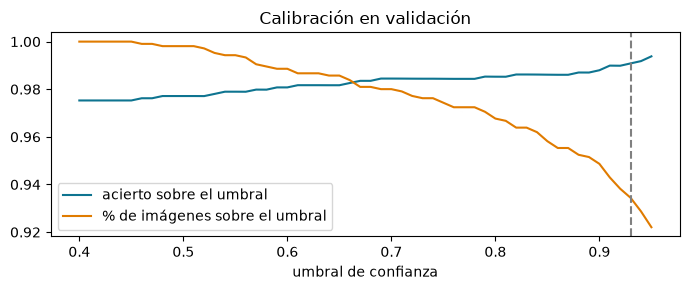

In [14]:
VALID = [(p, c) for c in CLASES for p in sorted((DATOS / "val" / c).iterdir())]
p_val, y_val = probs_yolo([p for p, _ in VALID]), np.array([CLASES.index(c) for _, c in VALID])
conf_val, ok_val = p_val.max(1), p_val.argmax(1) == y_val
candidatos = np.round(np.arange(0.40, 0.96, 0.01), 2)
acc_sobre = [ok_val[conf_val >= t].mean() for t in candidatos]
cobertura = [(conf_val >= t).mean() for t in candidatos]
UMBRAL = float(next((t for t, a in zip(candidatos, acc_sobre) if a >= 0.99), 0.90))

conf_test, ok_test = p_test.max(1), pred == Y_TEST
print(f"Umbral elegido: {UMBRAL:.2f}")
print(f"Prueba · sobre el umbral: {(conf_test >= UMBRAL).mean():.1%} de las imágenes con {ok_test[conf_test >= UMBRAL].mean():.1%} de acierto")
print(f"Prueba · bajo el umbral (a revisión humana): {(conf_test < UMBRAL).mean():.1%} con {ok_test[conf_test < UMBRAL].mean():.1%} de acierto")
print(f"Falsos negativos que quedan sobre el umbral: {(conf_test[fn] >= UMBRAL).sum()} de {len(fn)}")

plt.figure(figsize=(7, 3))
plt.plot(candidatos, acc_sobre, label="acierto sobre el umbral", color="#0e7490")
plt.plot(candidatos, cobertura, label="% de imágenes sobre el umbral", color="#e07b00")
plt.axvline(UMBRAL, ls="--", color="gray"); plt.xlabel("umbral de confianza"); plt.legend(); plt.title("Calibración en validación")
plt.tight_layout(); plt.show()

## 11. ¿Dónde mira el modelo? Grad-CAM

Grad-CAM pondera los mapas de activación de la última capa convolucional según cuánto influyen en la clase predicha. Es la misma idea de los *mapas de activación* de la Pauta 1, pero para un modelo preentrenado. Para YOLO recorremos su red capa por capa (es una lista de bloques de PyTorch) y nos quedamos con la salida de la última convolución. La app usa exactamente esta función.

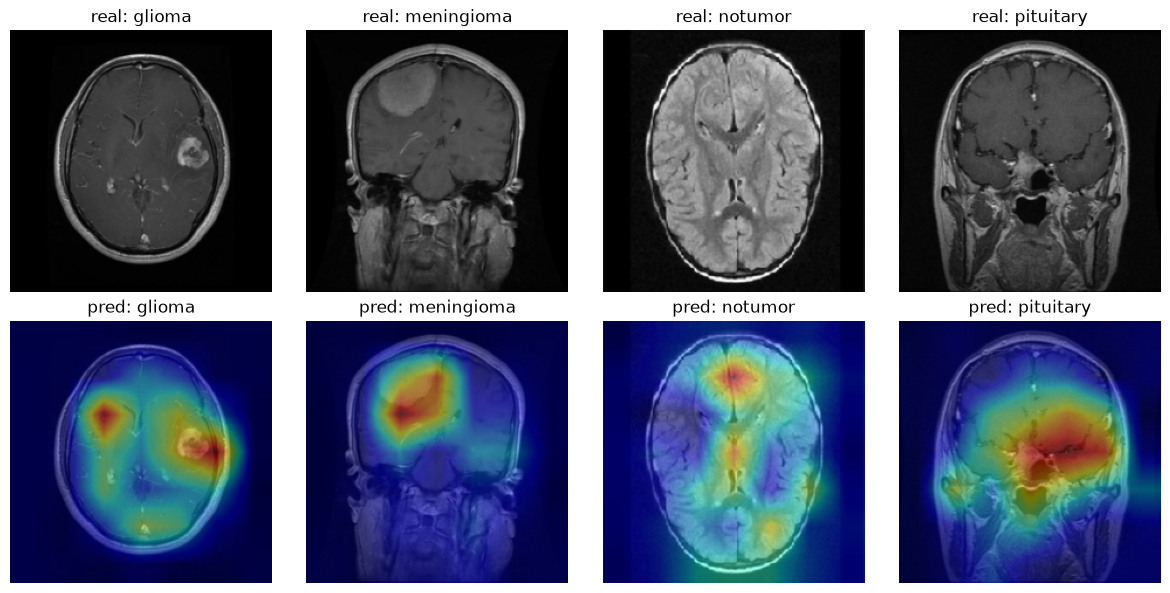

In [15]:
from torchvision import transforms
red = yolo.model.float().eval().to("cpu")
recorte = transforms.Compose([transforms.Resize(224), transforms.CenterCrop(224)])   # igual que YOLO

def gradcam(ruta):
    img = recorte(Image.open(ruta).convert("RGB"))
    x = transforms.ToTensor()(img).unsqueeze(0).requires_grad_()   # pide gradientes desde la entrada
    for capa in red.model[:-1]:            # bloques 0..9: extraen características
        x = capa(x)
    cabeza = red.model[-1]
    act = cabeza.conv(x); act.retain_grad()   # última convolución: 1280 mapas de 7×7
    logits = cabeza.linear(cabeza.pool(act).flatten(1))
    k = logits.argmax(1).item(); logits[0, k].backward()
    cam = torch.relu((act.grad.mean((2, 3), keepdim=True) * act).sum(1))[0]
    cam = torch.nn.functional.interpolate((cam / cam.max())[None, None], size=img.size[::-1], mode="bilinear")[0, 0]
    return img, cam.detach().numpy(), CLASES[k]

fig, ejes = plt.subplots(2, 4, figsize=(12, 6))
for j, c in enumerate(CLASES):
    ruta = next(p for p, cc in PRUEBA if cc == c)
    img, cam, k = gradcam(ruta)
    ejes[0, j].imshow(img); ejes[0, j].set_title(f"real: {c}"); ejes[0, j].axis("off")
    ejes[1, j].imshow(img); ejes[1, j].imshow(cam, cmap="jet", alpha=0.45); ejes[1, j].set_title(f"pred: {k}"); ejes[1, j].axis("off")
plt.tight_layout(); plt.show()

## 12. Exportar el modelo y los archivos que usa la app

In [16]:
INFO_CLASES = [
    {"id": "glioma", "nombre": "Glioma", "color": "#f472b6",
     "descripcion": "Tumor que nace de las células glía, que dan soporte a las neuronas. Suele infiltrarse en el tejido cerebral y tiene bordes irregulares."},
    {"id": "meningioma", "nombre": "Meningioma", "color": "#fbbf24",
     "descripcion": "Tumor de las meninges, las membranas que envuelven el cerebro. En general crece lento, es bien delimitado y con frecuencia es benigno."},
    {"id": "notumor", "nombre": "Sin tumor", "color": "#34d399",
     "descripcion": "El modelo no reconoce ninguno de los tres tipos de tumor entrenados en este corte. No descarta otras condiciones."},
    {"id": "pituitary", "nombre": "Tumor pituitario", "color": "#818cf8",
     "descripcion": "Tumor de la hipófisis, glándula en la base del cerebro que regula hormonas. La mayoría son adenomas benignos."},
]
(SALIDA / "clases.json").write_text(json.dumps({"clases": INFO_CLASES}, ensure_ascii=False, indent=2), encoding="utf-8")

cm = confusion_matrix(Y_TEST, pred)
metricas = {
    "modelo": "YOLO-cls nano", "accuracy": float(accuracy_score(Y_TEST, pred)),
    "balanced_accuracy": float(balanced_accuracy_score(Y_TEST, pred)), "n_test": int(len(Y_TEST)),
    "n_train": len(train), "n_val": len(val),
    "recall_por_clase": dict(zip(CLASES, map(float, recall_score(Y_TEST, pred, average=None)))),
    "precision_por_clase": dict(zip(CLASES, map(float, precision_score(Y_TEST, pred, average=None)))),
    "matriz_confusion": cm.tolist(), "sensibilidad_tumor": float(sens), "especificidad_tumor": float(esp),
    "falsos_negativos": int(len(fn)), "umbral": UMBRAL,
    "comparacion": [{"modelo": k, "balanced_accuracy": float(v["balanced_accuracy"]), "accuracy": float(v["accuracy"]),
                     "falsos_negativos": int(v["falsos_negativos"]),
                     "tamano_mb": round(float(v["tamano_mb"]), 1), "ms_por_imagen": round(float(v["ms_por_imagen"]), 1)}
                    for k, v in RESULTADOS.items()],
}
(SALIDA / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
shutil.copy(pesos_yolo, SALIDA / "yolo_cls.pt")      # pesos del modelo elegido (≈3 MB, cabe en GitHub)

# Imágenes de ejemplo (de PRUEBA) para el repositorio y la app: 1 por clase + 24 para el modo desafío
web = RAIZ / "web" / "public" / "ejemplos"; (web / "desafio").mkdir(parents=True, exist_ok=True)
(RAIZ / "ejemplos").mkdir(exist_ok=True)
rng, desafio = random.Random(SEMILLA), []
for c in CLASES:
    rutas = [p for p, cc in PRUEBA if cc == c]
    for destino in (RAIZ / "ejemplos" / f"{c}.jpg", web / f"{c}.jpg"):
        Image.open(rutas[0]).convert("RGB").save(destino, quality=90)
    desafio += [(r, c) for r in rng.sample(rutas[1:], 6)]
rng.shuffle(desafio)
lista = []
for k, (r, c) in enumerate(desafio):    # nombres neutros: el archivo no delata la clase
    img = Image.open(r).convert("RGB"); img.thumbnail((384, 384))
    img.save(web / "desafio" / f"{k:02d}.jpg", quality=85)
    lista.append({"archivo": f"desafio/{k:02d}.jpg", "clase": c})
(web / "desafio.json").write_text(json.dumps(lista, indent=1), encoding="utf-8")
print(json.dumps({k: v for k, v in metricas.items() if k != "comparacion"}, indent=1, ensure_ascii=False)[:800])

{
 "modelo": "YOLO-cls nano",
 "accuracy": 0.9838403041825095,
 "balanced_accuracy": 0.9840569877883312,
 "n_test": 1052,
 "n_train": 4909,
 "n_val": 1052,
 "recall_por_clase": {
  "glioma": 0.9664179104477612,
  "meningioma": 0.9925373134328358,
  "notumor": 1.0,
  "pituitary": 0.9772727272727273
 },
 "precision_por_clase": {
  "glioma": 0.9847908745247148,
  "meningioma": 0.9672727272727273,
  "notumor": 0.984375,
  "pituitary": 1.0
 },
 "matriz_confusion": [
  [
   259,
   5,
   4,
   0
  ],
  [
   2,
   266,
   0,
   0
  ],
  [
   0,
   0,
   252,
   0
  ],
  [
   2,
   4,
   0,
   258
  ]
 ],
 "sensibilidad_tumor": 0.995,
 "especificidad_tumor": 1.0,
 "falsos_negativos": 4,
 "umbral": 0.93
}


## 13. Conclusiones, riesgos y mejoras

**Resultado.** YOLO-cls nano ajustado con *transfer learning* clasifica las 4 clases con ≈98 % de accuracy balanceada en prueba, frente a ≈25 % de CLIP sin entrenar. La lección central del módulo se confirma: **un modelo preentrenado general no basta; adaptarlo con pocos datos del dominio lo cambia todo**.

**Error más costoso.** Los falsos negativos (tumor → "sin tumor") son pocos (≈0,5 % de los tumores), pero existen y algunos ocurren con confianza alta: **el umbral no los atrapa a todos**. Por eso la app nunca dice "descartado": siempre recomienda revisión profesional.

**Umbral.** Calibrado en validación, envía a revisión humana un pequeño porcentaje de imágenes, justo donde el modelo acierta mucho menos: la confianza sí es informativa.

**Riesgos / por qué desconfiar del ≈98 %.**
1. Sin identificador de paciente: cortes del mismo paciente pueden estar en train y test → métrica optimista.
2. "Sin tumor" proviene mayoritariamente de otra fuente (Br35H): el modelo podría aprender el estilo de la fuente.
3. Solo 3 tipos de tumor y un tipo de secuencia; una imagen fuera de ese mundo (otra patología, una foto cualquiera) igual recibirá una de las 4 etiquetas.

**Mejoras futuras.** Validar con un dataset externo (otro hospital), dividir por paciente, agregar una clase "fuera de distribución", y evaluar con radiólogos en un estudio real antes de cualquier uso clínico.